# Part 6: putting the models together, how many affordable units are at stake by 2035?

Four models answer four parts of "what is going to happen to affordable rental housing and what needs doing", each on its own evidence (`src/combined.py`):

| Piece | Model | What it gives, by state |
|---|---|---|
| Demand | Stock-flow scenarios (population by age and renter behavior, Part 4) | Extra affordable units needed to hold the 2023 affordable-unit ratio as extremely low income (ELI) renters change |
| Supply at risk 1 | Property-level rescue model for HOME and HUD-program subsidies (Part 5) | Units not rescued if the 2026 to 2035 subsidies lapse |
| Supply at risk 2 | State-effects exit model for LIHTC (Part 5b) | Units placed 1996 to 2005 expected to leave the monitoring list when each cohort reaches about 31 years |
| Supply at risk 3 | HUD-insured mortgage pathway from NHPD (Part 5d) | Units of properties whose only active subsidy is an insured loan, not already on the date-based list, expected to lose the mortgage by 2035 and not be rescued |

This is an accounting combination of four models, not a new fitted model, and it carries each piece's limits. The supply columns can overlap (a property with both a LIHTC and a HOME or HUD subsidy may
appear in both), the first is conditional on a lapse and so an upper bound, and the second counts leaving the monitoring list, not loss of affordability. The sum is used only to rank states and to give an order of magnitude.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import combined as C
from viz import apply_style, SERIES, save_figure, SURFACE, MUTED, BASELINE, INK_2, dot, tile_map, SEQUENTIAL

apply_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
t = C.units_at_stake()
t.to_csv("outputs/tables/units_at_stake_state.csv", index=False)

## 1. National totals

In [2]:
nat = pd.DataFrame({
    "low": [t.growth_need_baseline.sum(), t.nhpd_unrescued_lb.sum(), t.lihtc_leaving_adj.sum(), t.mortgage_lb.sum(), t.stake_low.sum()],
    "high": [t.growth_need_baseline.sum(), t.nhpd_unrescued_ub.sum(), t.lihtc_leaving.sum(), t.mortgage_ub.sum(), t.stake_high.sum()]},
    index=["growth: extra units to hold the 2023 ratio (baseline)", "HOME and HUD-program units not rescued if they lapse", "LIHTC units leaving the monitoring list", "HUD-insured mortgages ending early, not rescued", "total, order of magnitude"])
display(nat.round(0).astype(int))
g = t.growth_need_baseline.sum()
print(f"2023 base: {t.eli_renters.sum() / 1e6:.2f} million ELI renters, {t.afford_units.sum() / 1e6:.2f} million rent-affordable units. "
      f"Preservation pieces are {100 * (nat.iloc[1:4].sum() / nat.iloc[4]).min():.0f} to {100 * (nat.iloc[1:4].sum() / nat.iloc[4]).max():.0f} percent of the total")
print("which piece is largest, by state:", t.lead.value_counts().to_dict())
print(f"growth need is zero under the low scenario; under the high scenario it is {C.pd.read_csv('outputs/tables/scenarios_state.csv', dtype={'state_fips': str}).query('year == 2035 and scenario == \"high\"').extra_units_to_hold_2023_ratio.clip(lower=0).sum():,.0f} units")

,low,high
growth: extra units to hold the 2023 ratio (baseline),341444,341444
HOME and HUD-program units not rescued if they lapse,294898,352711
LIHTC units leaving the monitoring list,235693,296639
"HUD-insured mortgages ending early, not rescued",27810,42181
"total, order of magnitude",899845,1032975


2023 base: 10.92 million ELI renters, 5.85 million rent-affordable units. Preservation pieces are 62 to 67 percent of the total
which piece is largest, by state: {'nhpd': 25, 'growth': 16, 'lihtc': 10}
growth need is zero under the low scenario; under the high scenario it is 621,245 units


## 2. By state

Absolute units (the stack shows which piece drives each state), and units at stake per 100 ELI renters in 2023 (the intensity, which puts small and large states on one footing).

C:\Users\erick\AppData\Local\Temp\ipykernel_17900\4204669504.py:10: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


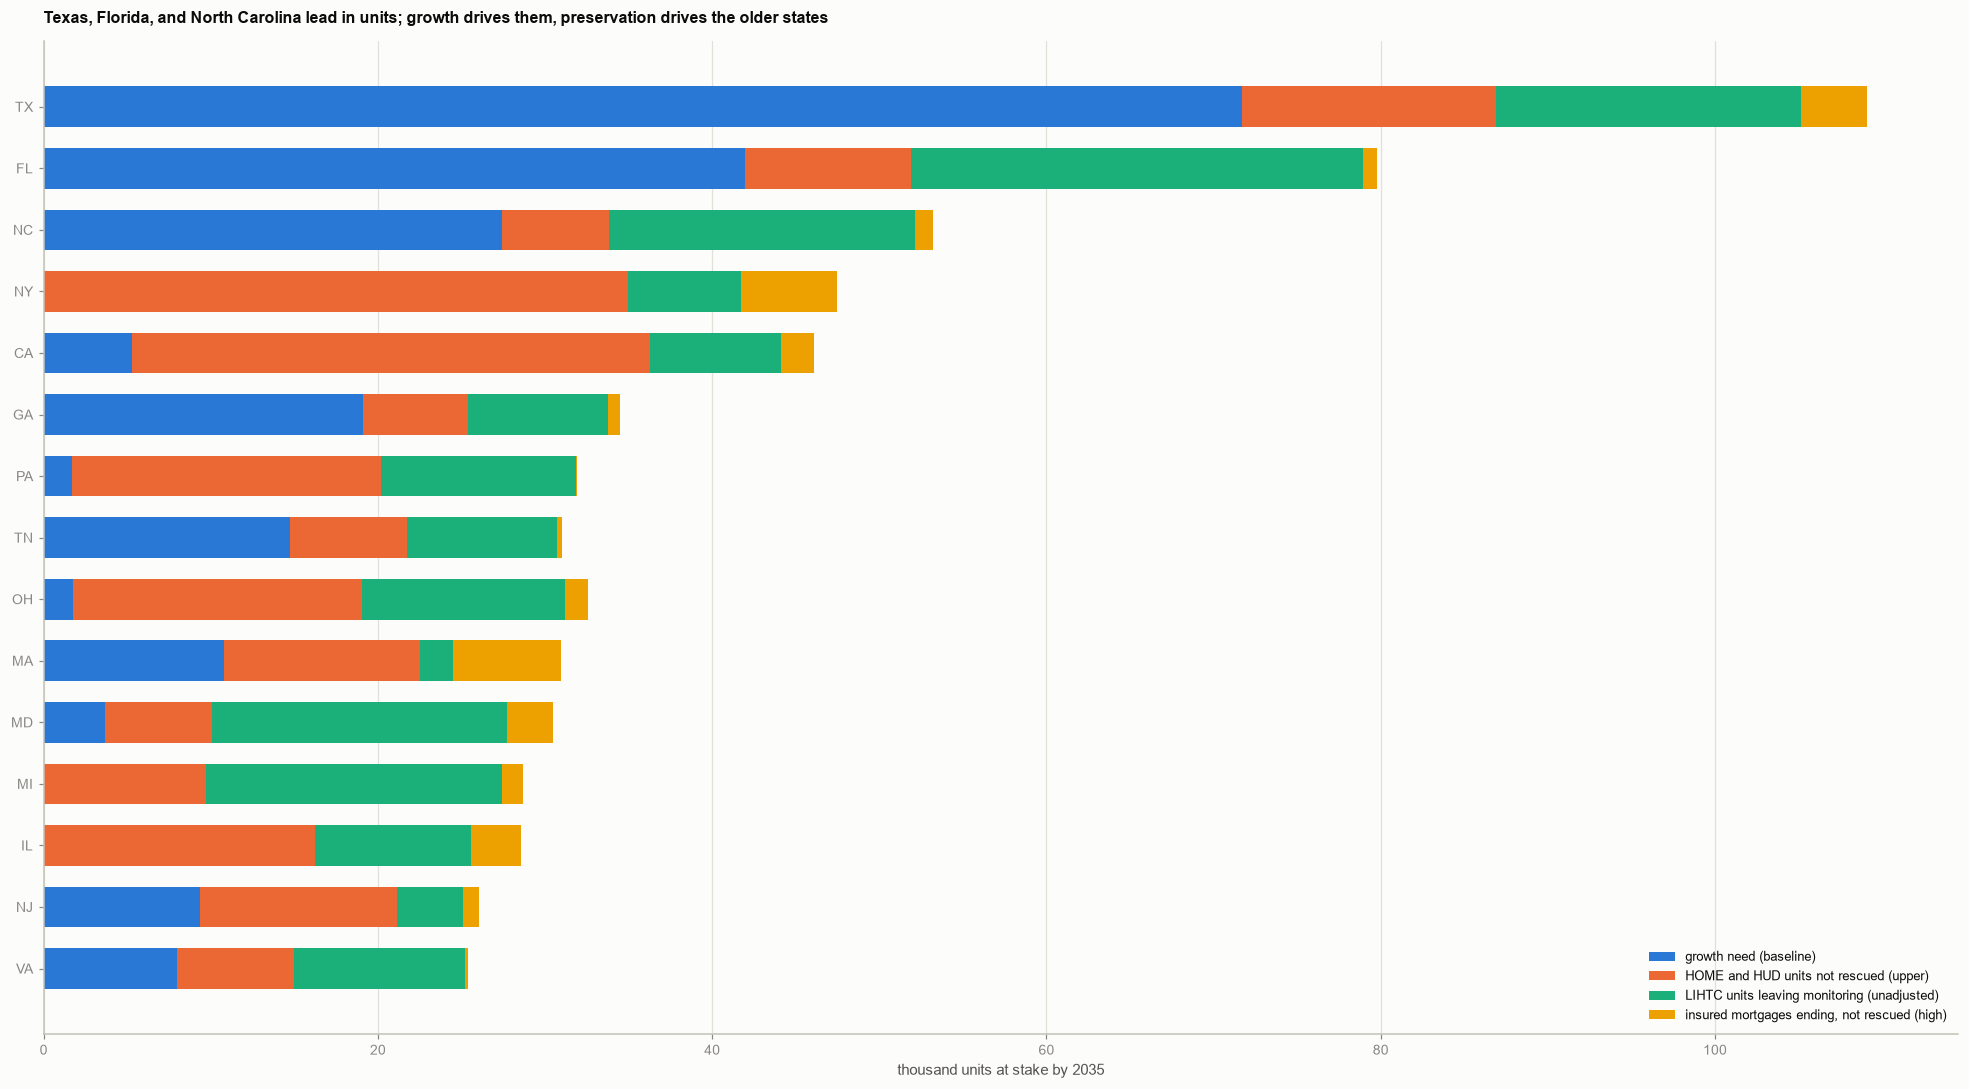

,state,stake_low,stake_high,growth_need_baseline,nhpd_unrescued_ub,lihtc_leaving,lead
0,TX,101555.0,109084.0,71706.0,15176.0,18250.0,growth
1,FL,72588.0,79762.0,41979.0,9943.0,27041.0,growth
2,NC,48373.0,53190.0,27397.0,6408.0,18342.0,growth
3,NY,37511.0,47484.0,0.0,34939.0,6783.0,nhpd
4,CA,38496.0,46094.0,5256.0,31035.0,7844.0,nhpd
5,GA,31026.0,34459.0,19103.0,6284.0,8404.0,growth
6,PA,28443.0,31903.0,1703.0,18464.0,11653.0,nhpd
7,TN,28871.0,31025.0,14759.0,6970.0,9013.0,growth
8,OH,26882.0,32587.0,1755.0,17307.0,12151.0,nhpd
9,MA,24993.0,30948.0,10778.0,11735.0,1977.0,nhpd


In [3]:
top = t.sort_values("stake_mid", ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(18, 10))
left = np.zeros(len(top))
for col, lab, c in (("growth_need_baseline", "growth need (baseline)", SERIES[0]), ("nhpd_unrescued_ub", "HOME and HUD units not rescued (upper)", SERIES[1]), ("lihtc_leaving", "LIHTC units leaving monitoring (unadjusted)", SERIES[2]), ("mortgage_ub", "insured mortgages ending, not rescued (high)", SERIES[3])):
    ax.barh(range(len(top)), top[col] / 1000, left=left, color=c, height=0.66, label=lab)
    left += top[col].values / 1000
ax.set_yticks(range(len(top)), top.state, fontsize=9); ax.grid(axis="y", visible=False)
ax.set_xlabel("thousand units at stake by 2035"); ax.legend(frameon=False, loc="lower right", fontsize=8.5)
ax.set_title("Texas, Florida, and North Carolina lead in units; growth drives them, preservation drives the older states", fontsize=10.5, loc="left")
fig.tight_layout()
save_figure(fig, "61_units_at_stake", part="06_combined")
plt.show()
display(t.sort_values("stake_mid", ascending=False).head(10)[["state", "stake_low", "stake_high", "growth_need_baseline", "nhpd_unrescued_ub", "lihtc_leaving", "lead"]].round(0).reset_index(drop=True))

,state,stake_mid,stake_per100_eli,stake_pct_of_afford_stock,lead
0,ID,9202.6,26.3,35.5,growth
1,SD,5506.1,21.0,21.7,growth
2,UT,11898.5,18.4,33.6,growth
3,NH,5746.4,16.1,26.3,nhpd
4,NC,50781.5,16.1,25.6,growth
5,SC,22006.8,15.8,24.2,growth
6,ME,6074.3,15.1,19.0,nhpd
7,ND,4196.3,14.2,16.9,growth
8,MD,27889.4,14.2,29.1,lihtc
9,MT,4529.2,14.2,16.9,growth


,state,stake_mid,stake_per100_eli,lead
0,CA,42295.1,3.0,nhpd
1,NY,42497.9,3.9,nhpd
2,IL,25208.2,5.7,nhpd
3,OR,7932.3,5.9,nhpd
4,NM,3490.6,6.0,nhpd


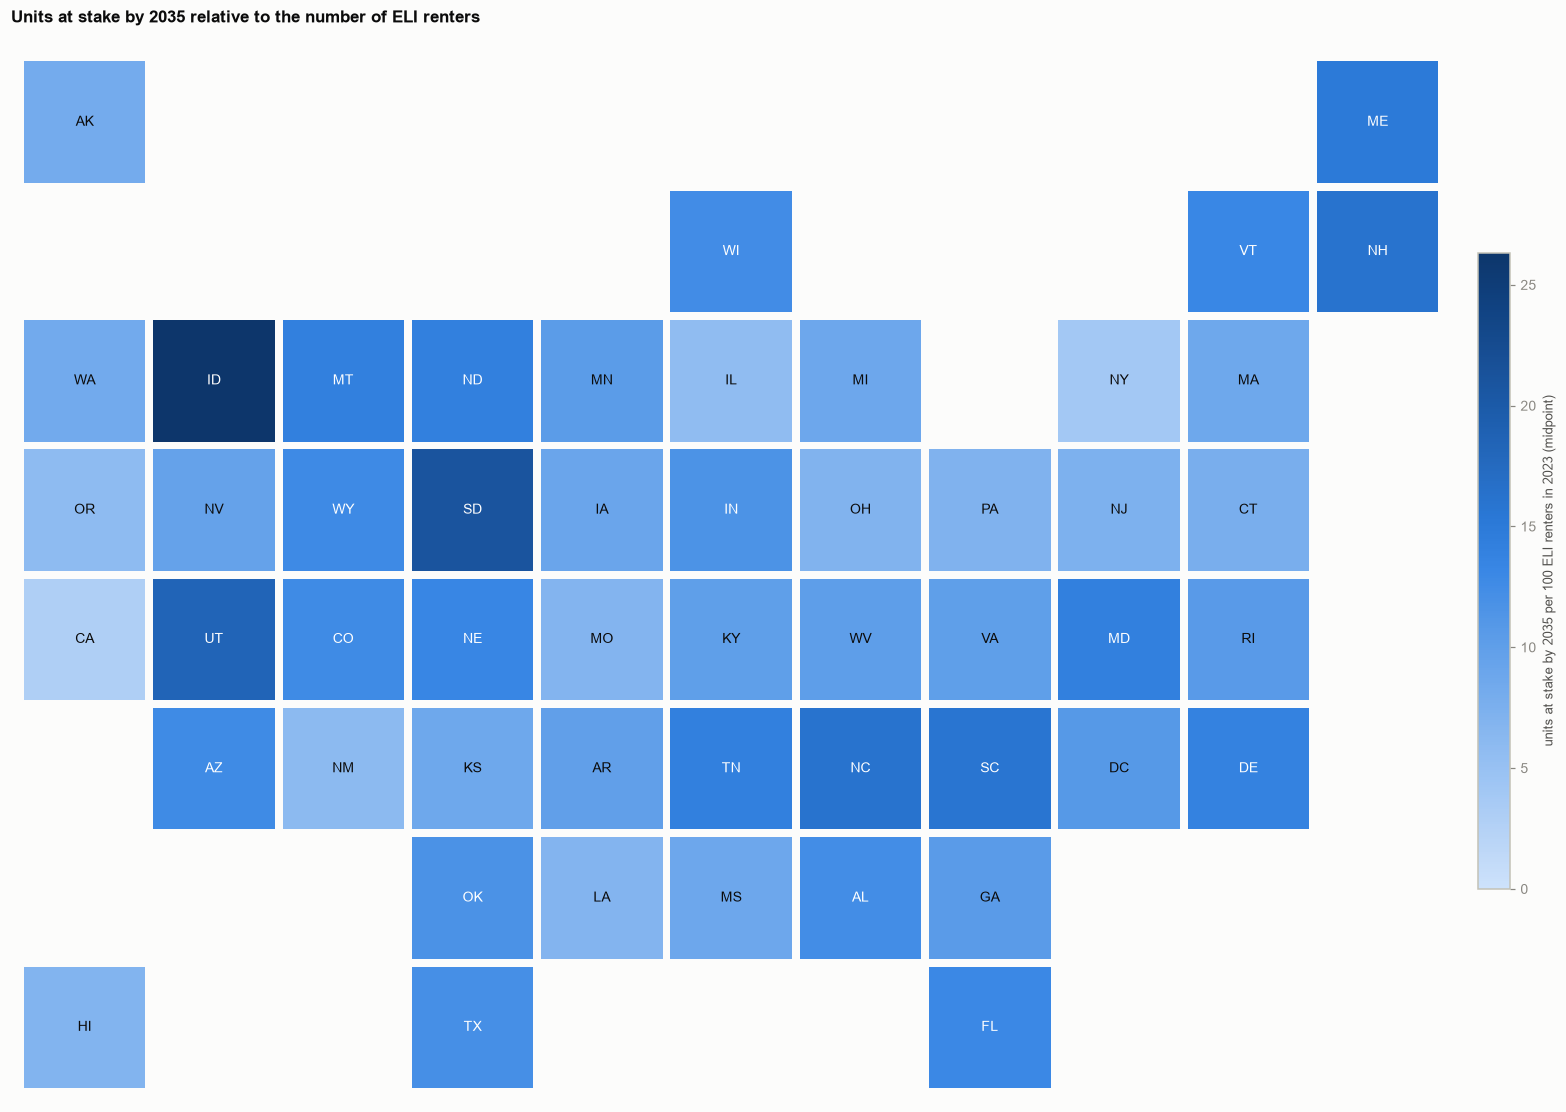

In [4]:
display(t.sort_values("stake_per100_eli", ascending=False).head(10)[["state", "stake_mid", "stake_per100_eli", "stake_pct_of_afford_stock", "lead"]].round(1).reset_index(drop=True))
display(t.sort_values("stake_per100_eli").head(5)[["state", "stake_mid", "stake_per100_eli", "lead"]].round(1).reset_index(drop=True))
fig, ax = plt.subplots(figsize=(18, 10))
v = t.set_index("state").stake_per100_eli
m = tile_map(ax, v, cmap=SEQUENTIAL, vmin=0, vmax=v.max())
cb = fig.colorbar(m, ax=ax, shrink=0.6, pad=0.01); cb.set_label("units at stake by 2035 per 100 ELI renters in 2023 (midpoint)", fontsize=8.5)
ax.set_title("Units at stake by 2035 relative to the number of ELI renters", fontsize=11, loc="left")
save_figure(fig, "61_stake_map", part="06_combined")
plt.show()

## 3. What kind of state is it?

The largest of the pieces labels each state: growth-led (more households than the stock keeps up with), HOME and HUD-led (subsidies lapsing without rescue), LIHTC-led (projects leaving monitoring), or mortgage-led (insured loans ending); no state is mortgage-led.

In [5]:
lead = t.groupby("lead").agg(states=("state", "size"), units=("stake_mid", "sum"), eli_renters=("eli_renters", "sum"))
lead["states_list"] = t.groupby("lead").apply(lambda d: ", ".join(d.sort_values("stake_mid", ascending=False).state.head(8)))
display(lead.round(0))

,states,units,eli_renters,states_list
lead,,,,
growth,16,419483.0,3252589.0,"TX, FL, NC, GA, TN, SC, AZ, WA"
lihtc,10,172738.0,1574381.0,"MD, MI, VA, WI, IN, CO, LA, NE"
nhpd,25,374189.0,6093382.0,"NY, CA, PA, OH, MA, IL, NJ, AL"


## Findings

**Order of magnitude.** By 2035 roughly **0.90 to 1.03 million** rent-affordable and subsidized units are at stake, against 10.9 million ELI renter households and 5.85 million rent-affordable units in 2023: about 341,000 extra units to hold today's affordable-unit
ratio under the baseline (nothing under the low scenario, 621,000 under the high one), 295,000 to 353,000 HOME and HUD-program units not rescued if their subsidies lapse, 236,000 to 297,000 LIHTC units leaving the monitoring list, and 28,000 to 42,000 units of properties
whose only subsidy is an insured mortgage that ends early. **The three preservation pieces are 62 to 67 percent of the total**, so on these definitions preserving what exists matters more than building for growth.

**By state, three kinds of state.** Growth is the largest piece in 16 states (Texas, Florida, North Carolina, Georgia, Tennessee, South Carolina, Arizona, Washington lead); subsidies lapsing without rescue is the largest in 25 (New York, California, Pennsylvania, Ohio, Massachusetts, Illinois,
New Jersey, Alabama); LIHTC leaving monitoring is the largest in 10 (Maryland, Michigan, Virginia, Wisconsin, Indiana, Colorado, Louisiana, Nebraska). The insured-mortgage piece is never the largest but is concentrated: Massachusetts, New York, Texas, Illinois, and Maryland.

**Largest in units:** Texas 102,000 to 109,000, Florida 73,000 to 80,000, North Carolina 48,000 to 53,000, New York 38,000 to 47,000, California 38,000 to 46,000, then Georgia, Pennsylvania, Tennessee. **Highest per 100 ELI renters:** Idaho 26, South Dakota 21, Utah 18, New Hampshire and North Carolina 16;
lowest California 3, New York 4, Illinois 6. The intensity measure puts small and large states on one footing but is a measure of *change by 2035*, not of today's gap: California and New York have large ELI renter populations and are already at the top of the need index (Part 1), so a low stake per 100 ELI renters does not mean
low need. Florida combines the highest need today (rank 1) with the second-largest stake.

**How to read it.** Each piece comes from a model with its own limits (Parts 4, 5, 5b, and 5d): scenarios are not forecasts, the rescue model covers only the HOME and HUD-program subsidies expiring 2026 to 2035 and gives an upper bound on loss, and the LIHTC piece counts leaving the monitoring list in states whose pattern may
be reporting practice. The pieces can overlap and the sum is for ranking and scale only. Table: `outputs/tables/units_at_stake_state.csv`.